# Exercise 6
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 6.1

Exact integral of $f(x) = \int_{-\infty}^\infty e^{-x^2}sin^2(x)$:

$$ sin^2(x) = \frac{1 - cos(2x)}{2} $$

$$ \int_{-\infty}^\infty e^{-x^2}sin^2(x) = \frac{1}{2}\int_{-\infty}^\infty e^{-x^2} - \frac{1}{2}\int_{-\infty}^\infty e^{-x^2}cos(2x) $$

Gauß'sche integral: $$ \int_{-\infty}^\infty e^{-x^2} = \sqrt{\pi} $$
Gauß Cosine Integral: $$ \int_{-\infty}^\infty e^{-x^2}cos(2x) = \sqrt{\pi} e^{-1} $$

Toether, we have:
$$ \int_{-\infty}^\infty e^{-x^2}sin^2(x) = \frac{\sqrt{\pi}}{2} - \frac{\sqrt{\pi}}{2} e^{-1} = \frac{\sqrt{\pi}}{2}(1 - e^{-1}) $$

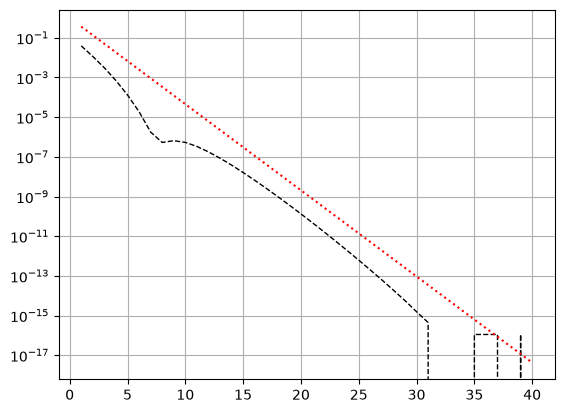

In [26]:
N = np.arange(1,41)
f = lambda x: np.exp(-x**2) * np.sin(x)**2
F = np.sqrt(np.pi) / 2 * (1 - np.exp(-1))

def simple_trapezoidal(f: callable, N: int):
    h = 1 / np.sqrt(N)
    x = np.arange(-N, N + 1) * h
    return h * np.sum(f(x))

error = np.zeros(len(N))
for i, n in enumerate(N):
    error[i] = np.abs(F - simple_trapezoidal(f=f, N=n))

plt.semilogy(N, error,"k--", lw=1,)
plt.semilogy(N, np.exp(-N), "r:", label=r"$e^{-N}$")
plt.grid(True)


## 6.2

An affine change is necessary to map the interval $[0, 1]$ to $[-1, 1]$:
$$ x = \frac{a + b}{2} + \frac{b - a}{2}t $$

$$ \int_0^1 f(x) dx \approx \frac{b - a}{2} \sum_i w_i f\left(\frac{a + b}{2} + \frac{b - a}{2}t_i\right)$$

In [ ]:
def affine_sum(f, weights, a, b, x):
    return (b - a) / 2 * np.sum(weights*f((a + b)/2 + (b - a)/2 * x))

def composite_gauss(f, n, L, q):
    """ Composite Gauss rule for integration over (0, 1) """
    # Computes the sample points and weights for Gauss-Legendre quadrature. These sample points and weights will 
    # correctly integrate polynomials of degree 2*deg - 1 or less over the interval [-1, 1] with the weight function f(x) = 1.
    x, w = np.polynomial.legendre.leggauss(deg=n) 

    # (0,qL−1),(qL−1,qL−2),(qL−2,qL−3)··· ,(q,1)
    qs = q**np.arange(L-1, -1, -1) # e.g. for q = 2 and L = 10: [512, 254, ..., 1]

    total = 0
    total += affine_sum(f, w, 0, q**(L-1), x) # doing the (0, q**L-1)
    for a, b in zip(qs[:-1], qs[1:]):
        total += affine_sum(f, w, a, b, x)
    return total

In [48]:
from itertools import product

m = [0, 1, 2]

# just some random combinations
ns = [1, 2, 3, 5]
Ls = [1, 2, 5, 10]
qs_test = [0.5, 0.15]

# (name, function, exact value of integral)
tests = [(f"x^{mm}", (lambda x, mm=mm: x**mm), 1 / (mm + 1)) for mm in m]
tests.append(("exp(x)", lambda x: np.exp(x), np.e - 1))

for n in ns:
    print(f"\n=== n = {n} (exact for degree <= {2*n - 1}) ===")
    print(f"{'f':>8} {'L':>3} {'q':>5} {'error':>12}")
    for (name, f, exact), L, q in product(tests, Ls, qs_test):
        err = abs(composite_gauss(f, n, L, q) - exact)
        print(f"{name:>8} {L:>3} {q:>5} {err:12.2e}")


=== n = 1 (exact for degree <= 1) ===
       f   L     q        error
     x^0   1   0.5     0.00e+00
     x^0   1  0.15     0.00e+00
     x^0   2   0.5     0.00e+00
     x^0   2  0.15     0.00e+00
     x^0   5   0.5     0.00e+00
     x^0   5  0.15     0.00e+00
     x^0  10   0.5     0.00e+00
     x^0  10  0.15     0.00e+00
     x^1   1   0.5     0.00e+00
     x^1   1  0.15     0.00e+00
     x^1   2   0.5     0.00e+00
     x^1   2  0.15     5.55e-17
     x^1   5   0.5     0.00e+00
     x^1   5  0.15     5.55e-17
     x^1  10   0.5     0.00e+00
     x^1  10  0.15     5.55e-17
     x^2   1   0.5     8.33e-02
     x^2   1  0.15     8.33e-02
     x^2   2   0.5     2.08e-02
     x^2   2  0.15     5.15e-02
     x^2   5   0.5     1.19e-02
     x^2   5  0.15     5.14e-02
     x^2  10   0.5     1.19e-02
     x^2  10  0.15     5.14e-02
  exp(x)   1   0.5     6.96e-02
  exp(x)   1  0.15     6.96e-02
  exp(x)   2   0.5     1.78e-02
  exp(x)   2  0.15     4.60e-02
  exp(x)   5   0.5     1.21e-02
 

+ $n \ge 2$: all monomials around $10^{-16}$, independent of $L$ and $q$
+ $n = 1$, $x^2$: a visible error that shrinks as $L$ grows
+ exp(x): small even at $n=1$, dropping very quickly with $n$

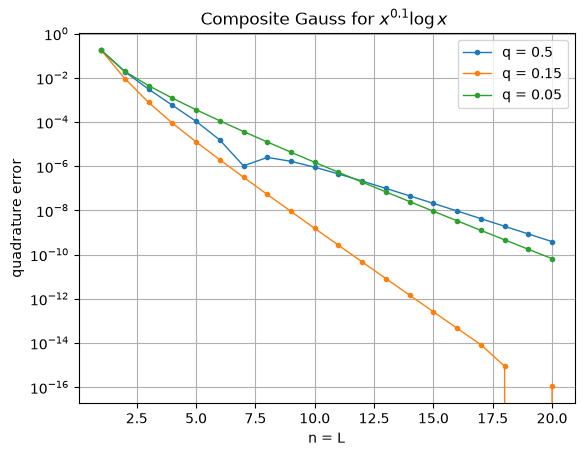

q =   0.5:  b = 0.934,  C = 2.018e-02
q =  0.15:  b = 1.864,  C = 2.424e-01
q =  0.05:  b = 1.089,  C = 1.149e-01


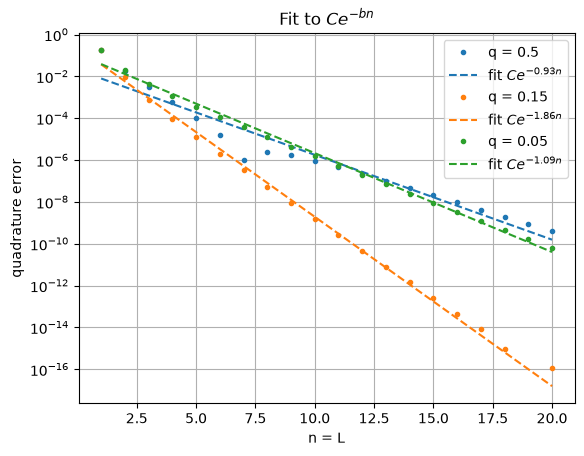

In [58]:
# b)
g = lambda x: x**0.1 * np.log(x)
exact_g = -1 / 1.1**2

n_vals = np.arange(1, 21)
q_vals = [0.5, 0.15, 0.05]

errors = {}
for q in q_vals:
    errors[q] = np.array([abs(composite_gauss(g, n, n, q) - exact_g) for n in n_vals])

plt.figure()
for q in q_vals:
    plt.semilogy(n_vals, errors[q], ".-", lw=1, label=f"q = {q}")
plt.xlabel("n = L")
plt.ylabel("quadrature error")
plt.title(r"Composite Gauss for $x^{0.1}\log x$ ")
plt.grid(True, which="both")
plt.legend()
plt.show()

# c)
tol = 1e-14 # exclude machine-precision 0s which would break the polyfit below!
plt.figure()
for q in q_vals:
    mask = errors[q] > tol
    slope, intercept = np.polyfit(n_vals[mask], np.log(errors[q][mask]), 1)
    b, C = -slope, np.exp(intercept)
    print(f"q = {q:>5}:  b = {b:.3f},  C = {C:.3e}")

    line, = plt.semilogy(n_vals, errors[q], ".", label=f"q = {q}")
    plt.semilogy(n_vals, C * np.exp(-b * n_vals), "--", color=line.get_color(),
                 label=rf"fit $C e^{{-{b:.2f} n}}$")
plt.xlabel("n = L")
plt.ylabel("quadrature error")
plt.title(r"Fit to $C e^{-bn}$")
plt.grid(True, which="both")
plt.legend()
plt.show()